# Toma de decisíones de negocio basadas en datos 

## Junto al equipo de marketing se recopilaron una lista de hipótesis que pueden ayudar a aumentar los ingresos

## Se priorizan estas hipótesis, se lanzará un test A/B para despues, analizar los resultados 

In [ ]:
#importacion de librerias para el analisis inicial
import pandas as pd 
import datetime as dt 
import numpy as np 
from scipy import stats as st 
import math as mth 
import matplotlib.pyplot as plt 
import scipy.stats as stats

### 1 Para la primera parte del analisis, revisaremos las 9 hipotesis sobre como aumentar los ingresos.

In [ ]:
hipotesis = pd.read_csv ('/datasets/hypotheses_us.csv',sep=';')

In [ ]:
print(hipotesis)

                                          Hypothesis  Reach  Impact  \
0  Add two new channels for attracting traffic. T...      3      10   
1  Launch your own delivery service. This will sh...      2       5   
2  Add product recommendation blocks to the store...      8       3   
3  Change the category structure. This will incre...      8       3   
4  Change the background color on the main page. ...      3       1   
5  Add a customer review page. This will increase...      3       2   
6  Show banners with current offers and sales on ...      5       3   
7  Add a subscription form to all the main pages....     10       7   
8  Launch a promotion that gives users discounts ...      1       9   

   Confidence  Effort  
0           8       6  
1           4      10  
2           7       3  
3           3       8  
4           1       1  
5           2       3  
6           8       3  
7           8       5  
8           9       5  


### 1.1 Aplicación del framework ICE 

In [ ]:
hipotesis['ICE'] = (
    hipotesis['Impact']
    * hipotesis['Confidence']
) / hipotesis['Effort']

print(hipotesis[['Hypothesis' , 'ICE']].sort_values(by='ICE', ascending=False))

                                          Hypothesis        ICE
8  Launch a promotion that gives users discounts ...  16.200000
0  Add two new channels for attracting traffic. T...  13.333333
7  Add a subscription form to all the main pages....  11.200000
6  Show banners with current offers and sales on ...   8.000000
2  Add product recommendation blocks to the store...   7.000000
1  Launch your own delivery service. This will sh...   2.000000
5  Add a customer review page. This will increase...   1.333333
3  Change the category structure. This will incre...   1.125000
4  Change the background color on the main page. ...   1.000000


### 1.1 Aplicación del framework RICE

In [ ]:
hipotesis['RICE'] = (hipotesis['Reach']
                     * hipotesis['Impact']
                     * hipotesis['Confidence']
                    ) / hipotesis['Effort']
print(hipotesis[['Hypothesis' , 'RICE']].sort_values(by='RICE',ascending=False))

                                          Hypothesis   RICE
7  Add a subscription form to all the main pages....  112.0
2  Add product recommendation blocks to the store...   56.0
0  Add two new channels for attracting traffic. T...   40.0
6  Show banners with current offers and sales on ...   40.0
8  Launch a promotion that gives users discounts ...   16.2
3  Change the category structure. This will incre...    9.0
1  Launch your own delivery service. This will sh...    4.0
5  Add a customer review page. This will increase...    4.0
4  Change the background color on the main page. ...    3.0


### La hipotesis tiene ICE alto por que es relativamente facil vs el impacto, pero en Rice sale bajo por que el Reach es chico, la hipotesis tiene RICE alto por que Reach es toda la base de usuarios pero en ICE seria bajisima.

### Elegir un solo framework por sesion de priorizacion, comparar peras con peras  es decir usar solo ICE o RICE. Sera una buena practica y facilitara los analisis futuros.

### 2 Análisis del test A/B 

In [ ]:
orders = pd.read_csv('/datasets/orders_us.csv', sep=',')
print(orders.head(5))

   transactionId   visitorId        date  revenue group
0     3667963787  3312258926  2019-08-15     30.4     B
1     2804400009  3642806036  2019-08-15     15.2     B
2     2961555356  4069496402  2019-08-15     10.2     A
3     3797467345  1196621759  2019-08-15    155.1     B
4     2282983706  2322279887  2019-08-15     40.5     B


In [ ]:
visits = pd.read_csv('/datasets/visits_us.csv', sep=',')
print(visits.head(5))

         date group  visits
0  2019-08-01     A     719
1  2019-08-02     A     619
2  2019-08-03     A     507
3  2019-08-04     A     717
4  2019-08-05     A     756


In [ ]:
# Matriz con valores unicos de parejas fecha-groups 
date_groups = orders[['date' , 'group']].drop_duplicates()

orders_aggregated = date_groups.apply(lambda x:orders[np.logical_and(
    orders['date'] <= x['date'], orders['group'] == x['group'])
    ].agg(
        {'date':'max',
         'group' : 'max',
         'transactionId' : pd.Series.nunique,
         'visitorId' : pd.Series.nunique, 
         'revenue' : 'sum'
    }),
axis=1,).sort_values(by=['date' , 'group'])

visits_aggregated = date_groups.apply(lambda x:visits[np.logical_and(
    visits['date'] <= x['date'], visits['group'] == x['group'])
    ].agg({'date' : 'max', 'group' : 'max', 'visits': 'sum'}),
    axis=1,).sort_values(by=['date' , 'group'])

In [ ]:
# Convertir fechas 
orders_aggregated['date'] = pd.to_datetime(orders_aggregated['date'])
visits_aggregated['date'] = pd.to_datetime(visits_aggregated['date'])

# Verificar tipos
print("Tipos después de conversión:")
print("orders_aggregated['date']:", orders_aggregated['date'].dtype)
print("visits_aggregated['date']:", visits_aggregated['date'].dtype)

Tipos después de conversión:
orders_aggregated['date']: datetime64[ns]
visits_aggregated['date']: datetime64[ns]


### Lo primero es formar una matriz que nos de valores unicos  de 'fecha' y 'grupo', aqui eliminamos duplicados. 
### Primero obtener las filas de orders, donde la fecha es menor o igual que la fecha del elemento 'date' 'group'y el grupo de prueba es el mismo que date group, despues agregamos fecha maxima, valor maximo para el grupo, numero de pedidos unicos e identificadores de usuarios y calculamos la suma del promedio, se hizo el mismo procedimiento con el DataFrame visits.


In [ ]:
# Hcer merge en las tablas obtenidas 

cumulative_data = orders_aggregated.merge(visits_aggregated, left_on=['date' , 'group'], right_on=['date' , 'group'])
cumulative_data.columns=['date', 'group', 'orders', 'buyers', 'revenue', 'visitors']


## Análisis test A/B 
## Paso 1
### Representacion grafica de el ingreso acumulado por grupo

In [ ]:
# Cumulative_revenue A/B aqui se almacena fecha, ingreso y numero de pedidos de grupo A/B 
cumulative_revenueA = cumulative_data[cumulative_data['group'] == 'A'][['date', 'revenue', 'orders']]
cumulative_revenueB = cumulative_data[cumulative_data['group'] == 'B'][['date', 'revenue', 'orders']]

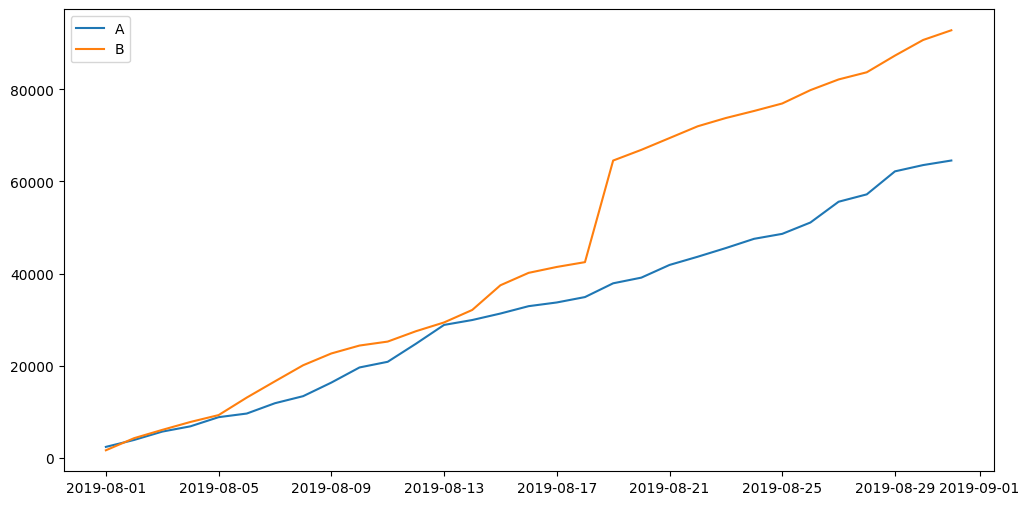

In [ ]:
plt.figure(figsize=(12,6))
plt.plot(cumulative_revenueA['date'], cumulative_revenueA['revenue'], label='A')
plt.plot(cumulative_revenueB['date'], cumulative_revenueB['revenue'], label='B')
plt.legend()
plt.show()

### El grupo 'A', se mantiene con una constante muy firme, con un ligero repunte em 2019-08-13, pero despues con una clara y muy fuerte constante. 
### El grupo 'B' crece a la par del grupo 'A' pero un poco despue de 201-08-17 presenta un aumento muy significativoque mantienen con ligeros decensos, lo cual nos puede sugerir, que el grupo 'B' tiene una mejor tza de consumo 

## Paso 2
### Representar graficamente el tamaño del pedido promedio acumulado por grupo 

In [ ]:
cumulative_ordersA = cumulative_data[cumulative_data['group'] == 'A'][['date', 'revenue', 'orders']]
cumulative_ordersB = cumulative_data[cumulative_data['group'] == 'B'][['date', 'revenue', 'orders']]

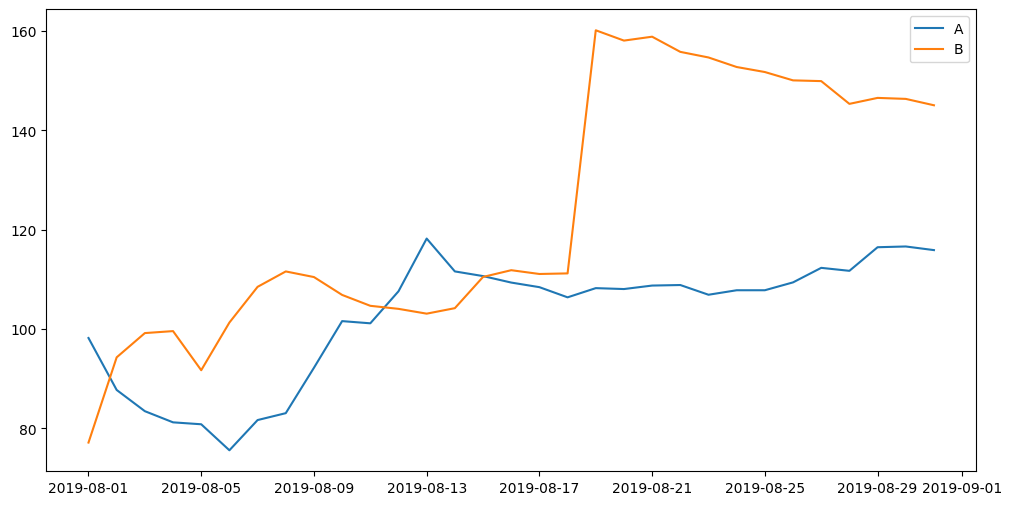

In [ ]:
plt.figure(figsize=(12,6))
plt.plot(cumulative_ordersA['date'],cumulative_ordersA['revenue']/cumulative_ordersA['orders'],label='A')
plt.plot(cumulative_ordersB['date'],cumulative_ordersB['revenue']/cumulative_ordersB['orders'],label='B')     
plt.legend()
plt.show()

### Tenemos un grupo 'A' que comienza a la baja lo cual puede ser algo necesariuo de evaluar, sin embargo, cerca de 2019-08-05 comienza un alza que se mantiene de manera constante, depues se etsabiliza y mantiene su curso.
### Po otro lado el grupo 'B' se mantiene al alza con picos gresivos de baja y alza lo cual puede ser debido a temporadas o quiza promociones que se presentan de acuerdo a la temporada. 

## Paso 3
### Rrepresentaion grafica de la diferencia relativa en el tamaño de pedido promedio acumulado para el grupo 'B' en comparacion con el grupo 'A'

In [ ]:
diferencia_relativa_AB = cumulative_ordersA.merge(cumulative_ordersB, left_on='date', right_on='date', how='left',suffixes=['A' , 'B'])

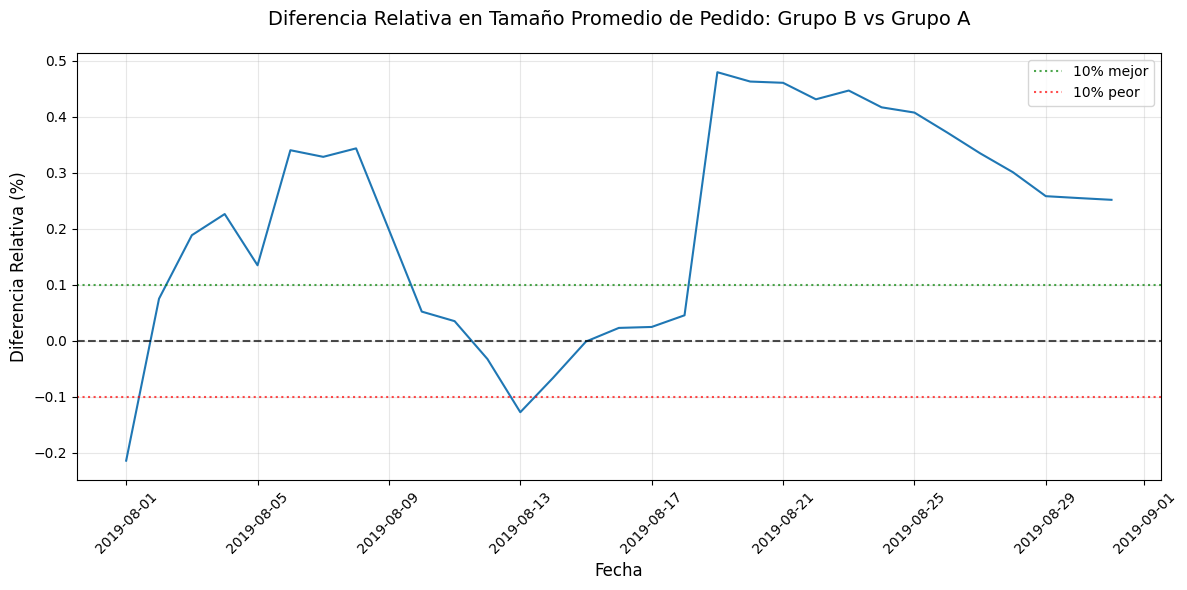

In [ ]:
plt.figure(figsize=(12,6))
plt.plot(diferencia_relativa_AB['date'],
         diferencia_relativa_AB['revenueB']/diferencia_relativa_AB['ordersB']/
         (diferencia_relativa_AB['revenueA']/diferencia_relativa_AB['ordersA'])-1)
plt.axhline(y=0, color='black', linestyle='--', alpha=0.7)
plt.axhline(y=0.1, color='green', linestyle=':', alpha=0.7, label='10% mejor')
plt.axhline(y=-0.1, color='red', linestyle=':', alpha=0.7, label='10% peor')
plt.title('Diferencia Relativa en Tamaño Promedio de Pedido: Grupo B vs Grupo A', fontsize=14, pad=20)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Diferencia Relativa (%)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show() 

### Al primcipio del periodo los grupos se comportan de manera similar, sin embargo en 2019-08-05 comienzan la diferenciar, el grupo 'B' se dispara y depues de 2019-08-17 el grupo 'B' comienza a tener mayor actividad 

## Paso 4
### calculo taza de conversion de cada grupo, como la relacion entre pedidos y el numero de visitas de cada dia

In [ ]:
daily_orders = orders.groupby(['date', 'group']).agg({'transactionId': 'nunique'}).reset_index()
daily_orders.columns = ['date', 'group', 'orders']

daily_visits = visits[['date', 'group', 'visits']].copy()

daily_data = daily_visits.merge(daily_orders, on=['date', 'group'], how='left')
daily_data['orders'] = daily_data['orders'].fillna(0)  # Llenar días sin pedidos con 0

daily_data['conversion'] = daily_data['orders'] / daily_data['visits']

# Separar daily_data por grupos para el gráfico de conversión
daily_dataA = daily_data[daily_data['group'] == 'A'][['date', 'conversion']]
daily_dataB = daily_data[daily_data['group'] == 'B'][['date', 'conversion']]

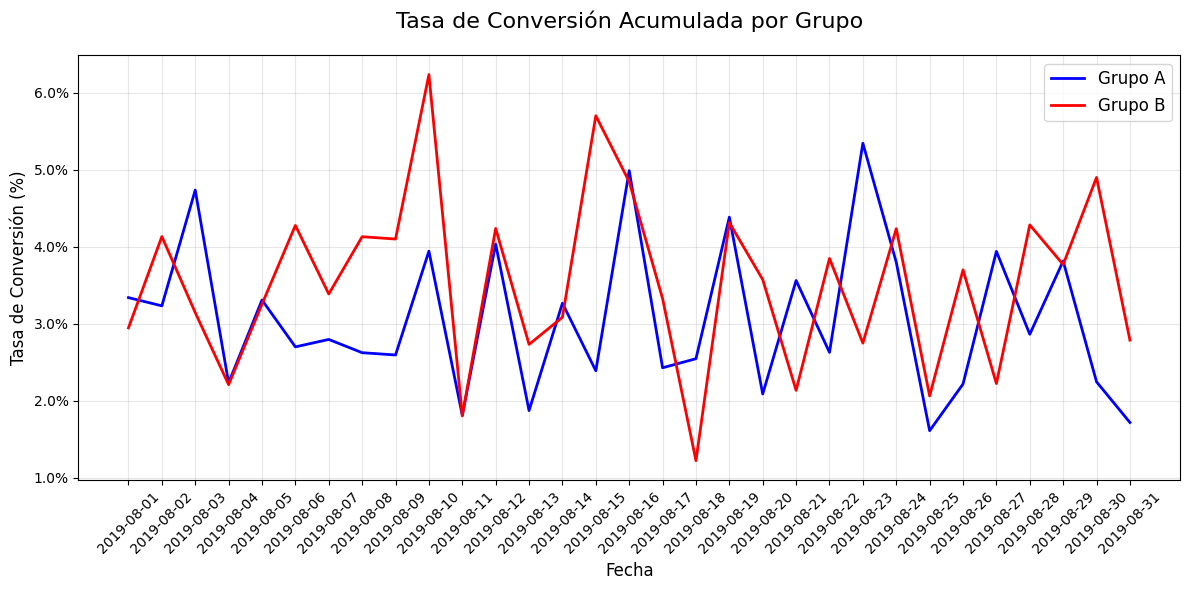

In [ ]:
plt.figure(figsize=(12,6))
plt.plot(daily_dataA['date'], daily_dataA['conversion'], 
         label='Grupo A', linewidth=2, color='blue')
plt.plot(daily_dataB['date'], daily_dataB['conversion'], 
         label='Grupo B', linewidth=2, color='red')

# Mejoras visuales
plt.title('Tasa de Conversión Acumulada por Grupo', fontsize=16, pad=20)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Tasa de Conversión (%)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)

# Formato de porcentaje en el eje Y
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: '{:.1%}'.format(y)))

plt.tight_layout()
plt.show()

### La tasa de conversion en el grupo 'A' tiene una estabilidad muy marcada, estando dentro del rango 2.1 , 2.2  a 5 pociento, tinen un ligero pico a la alza el dia 22 y una ligera baja el dia 24, lo cual podrian solo pequeñas animalias. 
### La tasa del grupo 'B'es bastante irregular, con picos agresibos que parecen fuera de rango en el dia 09 y un a picada inmininte en el dia 17 se mueve en un rango muy inestable entre el 3 y el 5 porciento.

## Paso 5 
### Greaqfico de dispersion del numero de pedidos por cliente.

In [ ]:
# Contar pedidos por usuario
orders_per_user = orders.groupby('visitorId').agg({
    'transactionId': 'count',  # Contar número de pedidos
    'revenue': 'sum',          # Suma total de ingresos por usuario
    'group': 'first'           # Grupo del usuario (A o B)
}).reset_index()

# Renombrar columnas para mayor claridad
orders_per_user.columns = ['visitorId', 'num_orders', 'total_revenue', 'group']

print("Primeros 5 usuarios:")
print(orders_per_user.head())

Primeros 5 usuarios:
   visitorId  num_orders  total_revenue group
0    5114589           1           10.8     B
1    6958315           1           25.9     B
2    8300375           2          196.2     B
3   11685486           1          100.4     A
4   39475350           1           65.4     B


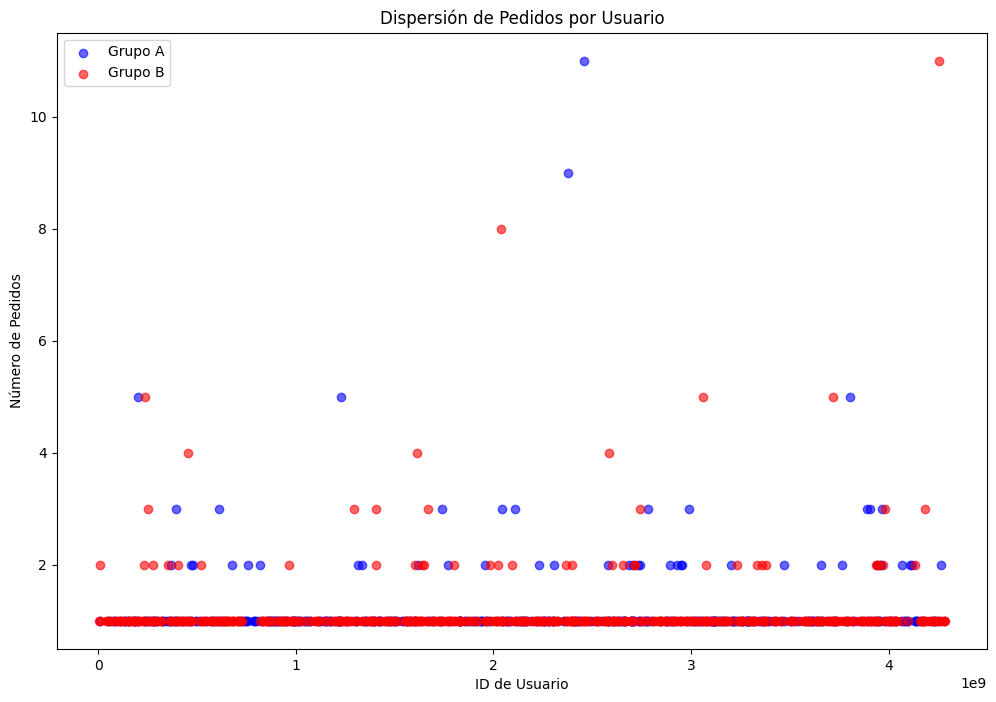

In [ ]:
# Separar por grupos
users_A = orders_per_user[orders_per_user['group'] == 'A']
users_B = orders_per_user[orders_per_user['group'] == 'B']

# Crear gráfico de dispersión
plt.figure(figsize=(12, 8))
plt.scatter(users_A['visitorId'], users_A['num_orders'], alpha=0.6, label='Grupo A', color='blue')
plt.scatter(users_B['visitorId'], users_B['num_orders'], alpha=0.6, label='Grupo B', color='red')
plt.xlabel('ID de Usuario')
plt.ylabel('Número de Pedidos')
plt.title('Dispersión de Pedidos por Usuario')
plt.legend()
plt.show()

### Se puede obcervar un rango de pedidos promedio de entre 1 a 3 pedidos, muy pocos usuarios tienen mas de 3 y la gran mayoria solo ha realizado uno

## Paso 6
### Calculo de percentiles 99 y 95 

In [ ]:

orders_per_user = orders.groupby('visitorId').agg({
    'transactionId': 'count',  # Contar número de pedidos
    'revenue': 'sum',          # Suma total de ingresos por usuario
    'group': 'first'           # Grupo del usuario (A o B)
}).reset_index()

# Renombrar columnas para mayor claridad
orders_per_user.columns = ['visitorId', 'num_orders', 'total_revenue', 'group']


print(np.percentile(orders_per_user['num_orders'], [95,99]))

[2. 4.]


In [ ]:
# Definir el umbral basado en el percentil 99
umbral_anomalo = 4

# Identificar usuarios anómalos (que superan el umbral)
usuarios_anomalos = orders_per_user[orders_per_user['num_orders'] > umbral_anomalo]

print(f"Total de usuarios anómalos: {len(usuarios_anomalos)}")
print(f"Total de usuarios en el dataset: {len(orders_per_user)}")
print(f"Porcentaje de usuarios anómalos: {len(usuarios_anomalos)/len(orders_per_user)*100:.2f}%")

Total de usuarios anómalos: 10
Total de usuarios en el dataset: 1031
Porcentaje de usuarios anómalos: 0.97%


In [ ]:
# Analizar por grupo
anomalos_A = usuarios_anomalos[usuarios_anomalos['group'] == 'A']
anomalos_B = usuarios_anomalos[usuarios_anomalos['group'] == 'B']

print("\n" + "="*50)
print("ANÁLISIS POR GRUPO")
print("="*50)
print(f"Usuarios anómalos en grupo A: {len(anomalos_A)}")
print(f"Usuarios anómalos en grupo B: {len(anomalos_B)}")


ANÁLISIS POR GRUPO
Usuarios anómalos en grupo A: 5
Usuarios anómalos en grupo B: 5


### Podemos considerar usar el percentil 99 (4 pedidos) como punto de corte para las anomalias, es mas sano y menos arriesgado, y nos dara informacion mas acertada

## Paso 7 
### Grafico de dispersion de precios de pedidos 

       visitorId  num_orders  total_revenue group
463   1920142716           1        19920.4     B
503   2108080724           1         3120.1     B
1023  4256040402          11         2751.2     B
1026  4266935830           2         2440.4     A
569   2378935119           9         2230.1     A


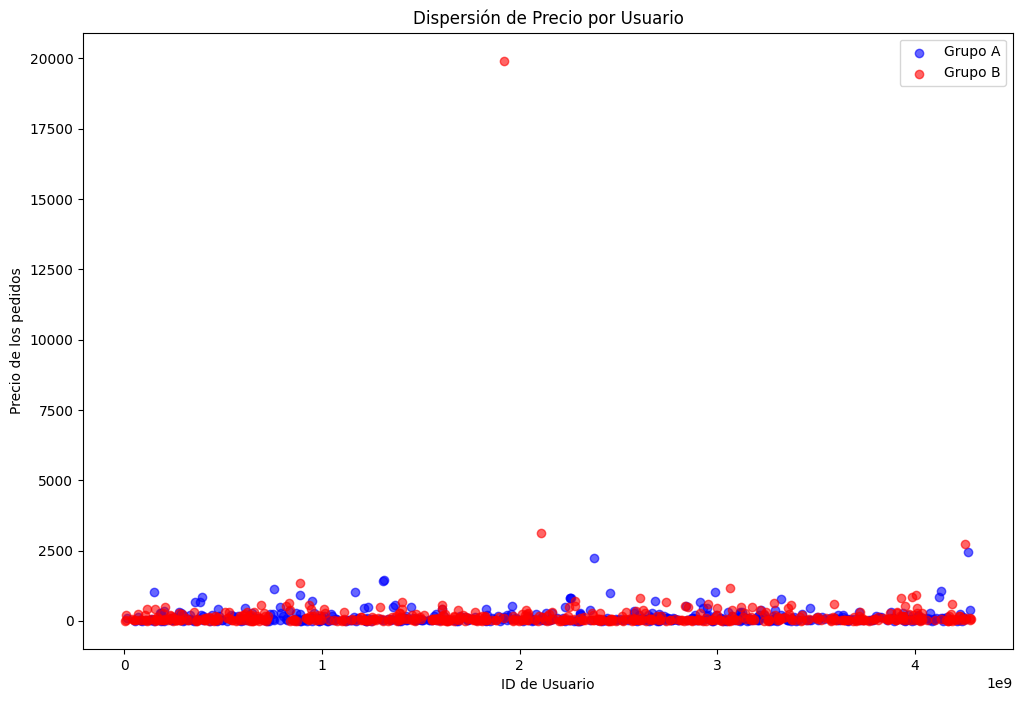

In [ ]:
print(orders_per_user.sort_values(by='total_revenue', ascending=False).head(5))

users_A = orders_per_user[orders_per_user['group'] == 'A']
users_B = orders_per_user[orders_per_user['group'] == 'B']

# Crear gráfico de dispersión
plt.figure(figsize=(12, 8))
plt.scatter(users_A['visitorId'], users_A['total_revenue'], alpha=0.6, label='Grupo A', color='blue')
plt.scatter(users_B['visitorId'], users_B['total_revenue'], alpha=0.6, label='Grupo B', color='red')
plt.xlabel('ID de Usuario')
plt.ylabel('Precio de los pedidos')
plt.title('Dispersión de Precio por Usuario')
plt.legend()
plt.show()

### El promedio por pedido es de 152.66 y la media del pedido es de 55.1

## Paso 8 
### Calculo de percentiles 95 y 99 del total de precio de pedidos. 

In [ ]:
orders_per_user = orders.groupby('visitorId').agg({
    'transactionId': 'count',  # Contar número de pedidos
    'revenue': 'sum',          # Suma total de ingresos por usuario
    'group': 'first'           # Grupo del usuario (A o B)
}).reset_index()

# Renombrar columnas para mayor claridad
orders_per_user.columns = ['visitorId', 'num_orders', 'total_revenue', 'group']

media = orders_per_user['total_revenue'].mean()
mediana = orders_per_user['total_revenue'].median()
percentiles = np.percentile(orders_per_user['total_revenue'], [95, 99])

print("=" * 50)
print("ANÁLISIS DE INGRESOS POR USUARIO")
print("=" * 50)
print(f"Media (promedio):     ${media:.2f}")
print(f"Mediana:              ${mediana:.2f}")
print(f"Percentil 95:         ${percentiles[0]:.2f}")
print(f"Percentil 99:         ${percentiles[1]:.2f}")
print("=" * 50)


ANÁLISIS DE INGRESOS POR USUARIO
Media (promedio):     $152.66
Mediana:              $55.10
Percentil 95:         $510.35
Percentil 99:         $1047.24


In [ ]:
# Definir el umbral basado en el percentil 99
umbral_anomalo = 1047

# Identificar usuarios anómalos (que superan el umbral)
usuarios_anomalos = orders_per_user[orders_per_user['total_revenue'] > umbral_anomalo]

print(f"Total de usuarios anómalos: {len(usuarios_anomalos)}")
print(f"Total de usuarios en el dataset: {len(orders_per_user)}")
print(f"Porcentaje de usuarios anómalos: {len(usuarios_anomalos)/len(orders_per_user)*100:.2f}%")

Total de usuarios anómalos: 11
Total de usuarios en el dataset: 1031
Porcentaje de usuarios anómalos: 1.07%


In [ ]:
# Analizar por grupo
anomalos_A = usuarios_anomalos[usuarios_anomalos['group'] == 'A']
anomalos_B = usuarios_anomalos[usuarios_anomalos['group'] == 'B']

print("\n" + "="*50)
print("ANÁLISIS POR GRUPO")
print("="*50)
print(f"Usuarios anómalos en grupo A: {len(anomalos_A)}")
print(f"Usuarios anómalos en grupo B: {len(anomalos_B)}")


ANÁLISIS POR GRUPO
Usuarios anómalos en grupo A: 6
Usuarios anómalos en grupo B: 5


### Usando el percentil 99 (1047) tenemos un umbral para considerar anomalias a que de 1031 usuarios solo 11 son tomados como anomalia, que es el 1.07 % esto no afectara la prueba A/B 

## Paso 9 
### Encontrar significancia estadistica de la diferencia en la conversion entre grupos con los datos en bruto.

In [ ]:
orders.columns,visits.columns

(Index(['transactionId', 'visitorId', 'date', 'revenue', 'group'], dtype='object'),
 Index(['date', 'group', 'visits'], dtype='object'))

In [ ]:
orders_by_usersA = orders[orders['group']=='A'].groupby('visitorId',as_index=False).agg({'transactionId' : 'count'})
orders_by_usersA.columns = ['visitorId','transactionId']
orders_by_usersA['transactionId'] = 1 
orders_by_usersB = orders[orders['group']=='B'].groupby('visitorId',as_index=False).agg({'transactionId' : 'count'})
orders_by_usersB.columns = ['visitorId','transactionId']
orders_by_usersB['transactionId'] = 1

In [ ]:
# CREAR UN SLICE DE DATOS DE GRUPO 'A'
usuarios_sin_ordenesA = visits[visits['group'] == 'A']['visits'].sum() - len(orders_by_usersA['transactionId'])

zeros_seriesA = pd.Series(0,index=np.arange(usuarios_sin_ordenesA), name ='transactionId')

sampleA = pd.concat([orders_by_usersA['transactionId'], zeros_seriesA], axis = 0) 

# CREAR UN SLICE DE DATOS DE GRUPO 'B'
usuarios_sin_ordenesB = visits[visits['group'] == 'B']['visits'].sum() - len(orders_by_usersB['transactionId'])

zeros_seriesB = pd.Series(0,index=np.arange(usuarios_sin_ordenesA), name ='transactionId')

sampleB = pd.concat([orders_by_usersB['transactionId'], zeros_seriesA], axis = 0)
          

In [ ]:
sampleA = pd.concat([orders_by_usersA['transactionId'], zeros_seriesA], axis = 0) 
sampleB = pd.concat([orders_by_usersB['transactionId'], zeros_seriesB], axis = 0)

print("{0:.5F}".format(stats.mannwhitneyu(sampleA, sampleB)[1]))
print("{0:.3f}".format(sampleB.mean() / sampleA.mean() -1))

0.01320
0.160


### P-valor: 0.08587 Diferencia relativa: 0.150 en el paso cuatro con los datos filtrados, P-valor 0.01320 y Difererncia relativa: 0.160, los datos sin tratamiento nos brinda un panaroma mas amplo, ademas de un valor p mas significativo al 0.05, adekmas de un 16% de mejora de conversion.

## Paso 10
### Enconrar la significancia estadistica de la diferencia en el tamaño promedio de pedido entre grupos utilizando los datos en bruto

In [ ]:
print("{0:3}".format(stats.mannwhitneyu(orders[orders['group'] == 'A']['revenue'], 
orders[orders['group'] == 'B']['revenue'],
)[1]))

print("{0:.3f}".format(
    orders[orders['group'] == 'B']['revenue'].mean()
    / orders[orders['group'] == 'A']['revenue'].mean()
    -1
))

0.6915246773264736
0.252


### El grupo B convierte mas usuarios, pero el tamaño de pedido no es estadisticamente diferente, quiza tenenmos valores atípicos afectando estos resultados 

## Paso 11 
### Significancia estadistica de la diferencia de conversion entre grupos con datos filtrados. 

In [ ]:
# Extraer solo las tasas de conversión diarias
conversion_rates_A = daily_dataA['conversion']
conversion_rates_B = daily_dataB['conversion']

# Aplicar la prueba de Mann-Whitney U
p_value = stats.mannwhitneyu(conversion_rates_A, conversion_rates_B)[1]
relative_difference = conversion_rates_B.mean() / conversion_rates_A.mean() - 1

print(f"P-valor: {p_value:.5f}")
print(f"Diferencia relativa: {relative_difference:.3f}")

P-valor: 0.08587
Diferencia relativa: 0.150


### La agregacion por dias reduce el poder estadistico, con los datos en bruto tenemos 23000 obcervaciones, con los datos filtrados solo 31 dias de datos, sugiero seguir con los datos en bruto para el anlisis.

## Paso 12
### Encontrar la significancia estadistica de la diferencia de tamaño promedio de pedido entre grupos con datos filtrados 

In [ ]:
users_whit_many_orders =pd.concat(
    [
        orders_by_usersA[orders_by_usersA['transactionId'] > 4]['visitorId'],
        orders_by_usersB[orders_by_usersB['transactionId'] > 4]['visitorId'],
    ],
    axis = 0
)
users_whit_expensive_orders = orders[orders['revenue'] > 1047]['visitorId']

abnormal_users = (pd.concat([users_whit_many_orders, users_whit_expensive_orders], axis=0)
    .drop_duplicates().sort_values())

print(abnormal_users.head(5))

744      888512513
1136    1307669133
858     1316129916
425     1920142716
1196    2108080724
Name: visitorId, dtype: int64


In [ ]:

sample_filtered_A = pd.concat([orders_by_usersA[np.logical_not(orders_by_usersA['visitorId'].isin(abnormal_users))]['transactionId'],pd.Series(0, index= np.arange(visits[visits['group'] == 'A']
['visits'].sum() - len(orders_by_usersA['transactionId'])), name= 'transactionId')], axis=0)

sample_filtered_B = pd.concat([orders_by_usersB[np.logical_not(orders_by_usersB['visitorId'].isin(abnormal_users))]['transactionId'],pd.Series(0, index= np.arange(visits[visits['group'] == 'B']
['visits'].sum() - len(orders_by_usersB['transactionId'])), name= 'transactionId')], axis=0)

print("P- Valor: {0:.5F}".format(stats.mannwhitneyu(sample_filtered_A , sample_filtered_B)[1]))
print("Conversion promedio: {0:.3f}".format(sample_filtered_B.mean() / sample_filtered_A.mean()-1))

P- Valor: 0.01763
Conversion promedio: 0.153


### Esto es bueno, por que significa que incluso despues de filtrar los valores atipicos, la diferencia entre grupos sigue siendo estadisticamente significativa. Antes del filtrado (datos en bruto):- P-valor: 0.01320- Diferencia relativa: 0.160 (16.0%) . Después del filtrado: - P-valor: 0.01763  - Diferencia relativa: 0.153 (15.3%). Los valores atípicos no estaban afectando significativamente los resultados de la prueba.

## Paso 13 

### La decisión mas sensata hasta este punto, es paraqr la prueba, el grupo B es lider con el 15.3% de mejor conveersion.

### Se tomarón en cuenta los datos crudos y tratados, y en ambas condiciones el grupo B lidereo, tenemos evidencia solida y no es necessario extender mas la prueba, se recomienda impulsar al grupo B con mas acciones de publicidad o marketing, ya que sus picos fueron en dias muy especificos, pero durantre el periodo de tiempo, se mantubo con paso firme y constante.

### Quedo a sus ordenes para cualquier aclaracion, saludos ATTE. Cesar Rodriguez, Analista Junior